## 1. Import libraries
We use Pandas, Matplotlib, Seaborn, and Scikit-learn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
sns.set_theme(style='whitegrid')
print('Libraries imported successfully.')

Libraries imported successfully.


In [2]:
iris = load_iris(as_frame=True)
X = iris.data.copy()
y_true = iris.target.copy()
df = X.copy()
df['true_species'] = [iris.target_names[i] for i in y_true]
print('Dataset shape:', df.shape)
display(df.head())
print(df['true_species'].value_counts())

Dataset shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),true_species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


true_species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Scaled data shape:', X_scaled.shape)

Scaled data shape: (150, 4)


## 4. Apply K-Means (k=3)

In [4]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df['cluster'] = clusters
print('Cluster counts:')
print(df['cluster'].value_counts().sort_index())
print('Silhouette score:', round(silhouette_score(X_scaled, clusters), 4))

Cluster counts:
cluster
0    53
1    50
2    47
Name: count, dtype: int64
Silhouette score: 0.4599


C:\Users\AKSHAT GUPTA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


## 5. Apply PCA to reduce dimensions
PCA projects four standardized features into two components for visualization.

In [5]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plot_df = pd.DataFrame({'PC1': X_pca[:, 0], 'PC2': X_pca[:, 1], 'cluster': clusters, 'true_species': [iris.target_names[i] for i in y_true]})
print('Explained variance ratio:', np.round(pca.explained_variance_ratio_, 4))
print('Total variance explained:', round(pca.explained_variance_ratio_.sum(), 4))

Explained variance ratio: [0.7296 0.2285]
Total variance explained: 0.9581


## 6. Visualize K-Means clusters

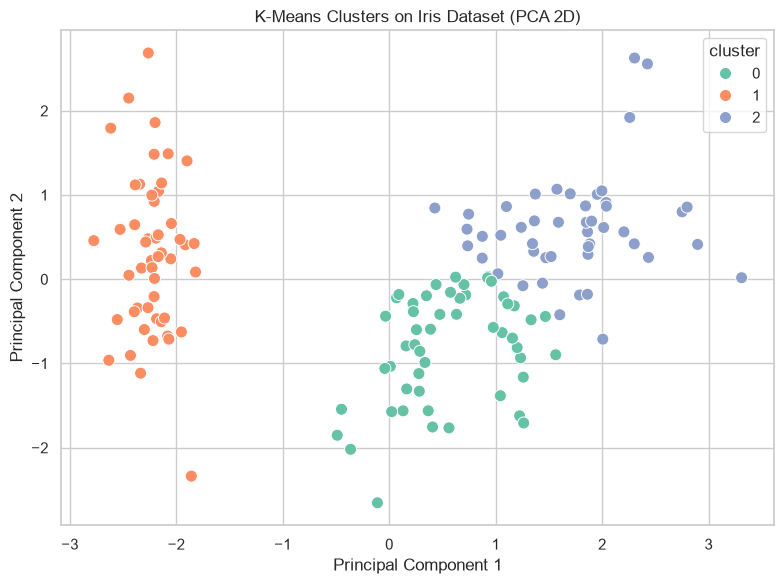

In [6]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='cluster', palette='Set2', s=75)
plt.title('K-Means Clusters on Iris Dataset (PCA 2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.tight_layout()
plt.show()

In [7]:
comparison = pd.crosstab(pd.Series(plot_df['true_species'], name='True Species'), pd.Series(plot_df['cluster'], name='K-Means Cluster'))
display(comparison)
ari = adjusted_rand_score(y_true, clusters)
print(f'Adjusted Rand Index (ARI): {ari:.4f}')

K-Means Cluster,0,1,2
True Species,,,
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36


Adjusted Rand Index (ARI): 0.6201


## 8. Plot true species labels

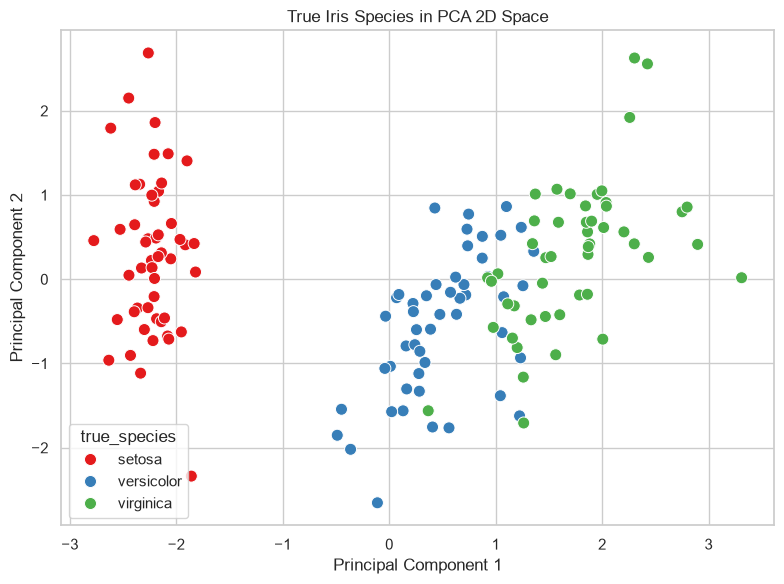

In [8]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='true_species', palette='Set1', s=75)
plt.title('True Iris Species in PCA 2D Space')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.tight_layout()
plt.show()